# Kaggle Competition — RiskScore Prediction

### Цель: построить модель линейной регрессии для предсказания RiskScore и оценить качество по MSE.

1. Импорт библиотек и загрузка данных

In [141]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("ex.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Sample submission:", sample_submission.shape)

display(train.head())
display(test.head())

Train: (11017, 35)
Test: (5000, 35)
Sample submission: (5000, 2)


,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,...,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0,66829.0,549.0,17290.0,60.0,Divorced,1.0,Rent,1095.0,...,4.0,Employed,Associate,4.0,35067.0,0.257790,0.251465,508.970230,0.288013,66.176500
1,1996-09-23,55.0,172147.0,850.0,16110.0,36.0,Widowed,1.0,Mortgage,211.0,...,2.0,Employed,High School,33.0,27001.0,0.086110,0.093173,514.675859,0.050585,28.495737
2,2015-01-19,51.0,300000.0,850.0,38436.0,36.0,Married,0.0,Mortgage,546.0,...,3.0,Employed,Bachelor,28.0,278382.0,0.108436,0.115443,1268.276385,0.072571,34.488104
3,1981-05-12,25.0,34683.0,847.0,19186.0,48.0,Married,0.0,Other,153.0,...,3.0,Employed,High School,0.0,9224.0,0.100686,0.112822,498.505187,0.225415,36.910753
4,1995-05-07,55.0,300000.0,850.0,30437.0,48.0,Single,2.0,Rent,562.0,...,5.0,Employed,Bachelor,31.0,4502.0,0.110437,0.089037,756.035156,0.052721,31.347091


,ID,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,...,UtilityBillsPaymentHistory,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio
0,0,1979-01-03,49,207095,850,14458,60,Single,0,Rent,...,0.883232,6,Employed,High School,23,10626,0.104458,0.125350,325.532336,0.040650
1,1,2006-04-10,28,64653,674,65491,48,Single,2,Own,...,0.791928,3,Employed,High School,3,299024,0.233491,0.260561,2210.247757,0.454410
2,2,2013-11-28,41,300000,768,16811,60,Single,1,Own,...,0.805826,3,Employed,High School,19,6979,0.147811,0.154571,403.977431,0.034919
3,3,1995-08-24,50,300000,850,48737,36,Divorced,0,Mortgage,...,0.829294,3,Self-Employed,Bachelor,26,8438,0.118737,0.099712,1571.946906,0.085558
4,4,1980-06-15,35,300000,672,51916,60,Single,6,Mortgage,...,0.735013,7,Employed,Associate,12,436216,0.230916,0.237727,1486.675235,0.063707


2. Проверка и очистка целевой переменной

In [142]:
print("Пропуски в RiskScore:", train["RiskScore"].isna().sum())
print("Маркер -9999999:", (train["RiskScore"] == -9999999).sum())
print("Маркер 10000000:", (train["RiskScore"] == 10000000).sum())

train_model = train[
    train["RiskScore"].notna()
    & train["RiskScore"].between(0, 100)
].copy()

print("Размер исходного train:", train.shape)
print("Размер train_model:", train_model.shape)
display(train_model["RiskScore"].describe())

Пропуски в RiskScore: 530
Маркер -9999999: 121
Маркер 10000000: 94
Размер исходного train: (11017, 35)
Размер train_model: (10272, 35)


count    10272.000000
mean        48.358094
std         17.241456
min         14.841417
25%         32.722756
50%         44.195792
75%         65.124190
max         97.597249
Name: RiskScore, dtype: float64

3. Разделение на обучающую и проверочную выборки

In [143]:
X = train_model.drop(columns=["RiskScore"])
y = train_model["RiskScore"].astype(float)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

X_train: (8217, 34)
X_val: (2055, 34)


4. Подготовка признаков

In [144]:
def add_date_features(df):
    df = df.copy()
    date = pd.to_datetime(df["ApplicationDate"], errors="coerce")
    df["ApplicationYear"] = date.dt.year
    df["ApplicationMonth"] = date.dt.month
    df["ApplicationDay"] = date.dt.day
    return df.drop(columns=["ApplicationDate"])

X_train = add_date_features(X_train)
X_val = add_date_features(X_val)

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Числовых признаков:", len(numeric_features))
print("Категориальные признаки:", categorical_features)

Числовых признаков: 31
Категориальные признаки: ['MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose', 'EmploymentStatus', 'EducationLevel']


Заполнение пропусков

In [145]:
numeric_medians = X_train[numeric_features].median()
categorical_modes = X_train[categorical_features].mode().iloc[0]

X_train[numeric_features] = X_train[numeric_features].fillna(numeric_medians)
X_val[numeric_features] = X_val[numeric_features].fillna(numeric_medians)

X_train[categorical_features] = X_train[categorical_features].fillna(categorical_modes)
X_val[categorical_features] = X_val[categorical_features].fillna(categorical_modes)

print("Пропуски в X_train:", X_train.isna().sum().sum())
print("Пропуски в X_val:", X_val.isna().sum().sum())

Пропуски в X_train: 0
Пропуски в X_val: 0


One-Hot Encoding

In [146]:
X_train = pd.get_dummies(X_train, columns=categorical_features, dtype=int)
X_val = pd.get_dummies(X_val, columns=categorical_features, dtype=int)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)

print("Размер X_train:", X_train.shape)
print("Размер X_val:", X_val.shape)

Размер X_train: (8217, 52)
Размер X_val: (2055, 52)


Доп рефакторинг

In [180]:
for frame in [X_train, X_val]:

    # Нелинейное влияние дохода
    frame["Log_MonthlyIncome"] = np.log1p(
        frame["MonthlyIncome"].clip(lower=0)
    )

    # Нелинейное влияние кредитного рейтинга
    frame["CreditScore_sq"] = frame["CreditScore"] ** 2

    # Нелинейное влияние активов
    frame["Log_TotalAssets"] = np.log1p(
        frame["TotalAssets"].clip(lower=0)
    )

    # Нелинейное влияние базовой процентной ставки
    frame["BaseInterestRate_sq"] = (
        frame["BaseInterestRate"] ** 2
    )

    # Нелинейное влияние долговой нагрузки
    frame["Log_TotalDebtToIncomeRatio"] = np.log1p(
        frame["TotalDebtToIncomeRatio"].clip(lower=0)
    )

    # Новые преобразования

    # Логарифм годового дохода
    frame["Log_AnnualIncome"] = np.log1p(
        frame["AnnualIncome"].clip(lower=0)
    )

    # Квадрат процентной ставки
    frame["InterestRate_sq"] = (
        frame["InterestRate"] ** 2
    )

    # Квадрат долговой нагрузки
    frame["TotalDebtToIncomeRatio_sq"] = (
        frame["TotalDebtToIncomeRatio"] ** 2
    )

print("Количество признаков:", X_train.shape[1])
print("Train:", X_train.shape)
print("Validation:", X_val.shape)


Количество признаков: 62
Train: (8217, 62)
Validation: (2055, 62)


Z-score нормализация

In [181]:
z_mean = X_train.mean()
z_std = X_train.std(ddof=0).replace(0, 1)

X_train_z = ((X_train - z_mean) / z_std).astype(float)
X_val_z = ((X_val - z_mean) / z_std).astype(float)

print("Пропуски после нормализации:", X_train_z.isna().sum().sum())
print("Размеры:", X_train_z.shape, X_val_z.shape)

Пропуски после нормализации: 0
Размеры: (8217, 62) (2055, 62)


5. Собственная линейная регрессия

In [182]:
class MyLinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        X_bias = np.c_[np.ones(X.shape[0]), X]
        self.weights = np.linalg.pinv(X_bias) @ y
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        X_bias = np.c_[np.ones(X.shape[0]), X]
        return X_bias @ self.weights

model = MyLinearRegression()
model.fit(X_train_z, y_train)

y_pred = model.predict(X_val_z)

Базовые метрики

In [183]:
mse = mean_squared_error(y_val, y_pred)
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2:  {r2:.4f}")

MSE: 37.0894
MAE: 4.7083
R2:  0.8760


6. Анализ ошибок модели

In [184]:
errors = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Predicted": y_pred
})
errors["Error"] = errors["Actual"] - errors["Predicted"]
errors["AbsoluteError"] = errors["Error"].abs()
errors["SquaredError"] = errors["Error"] ** 2

print("Средняя ошибка:", errors["Error"].mean())
print("Медианная абсолютная ошибка:", errors["AbsoluteError"].median())
print("95-й процентиль абсолютной ошибки:", errors["AbsoluteError"].quantile(0.95))

display(errors.sort_values("AbsoluteError", ascending=False).head(15))

Средняя ошибка: -0.12341965066253713
Медианная абсолютная ошибка: 3.8174862683080235
95-й процентиль абсолютной ошибки: 12.38698106262075


,Actual,Predicted,Error,AbsoluteError,SquaredError
2035,40.184554,66.059249,-25.874695,25.874695,669.499849
1645,40.184554,66.059249,-25.874695,25.874695,669.499849
394,45.041600,68.770410,-23.728810,23.728810,563.056428
1757,40.996571,64.227123,-23.230552,23.230552,539.658555
160,74.327407,51.566238,22.761169,22.761169,518.070814
517,68.778003,47.700189,21.077814,21.077814,444.274235
1016,81.241185,60.422612,20.818573,20.818573,433.412962
1139,38.764392,59.303113,-20.538721,20.538721,421.839061
1912,47.595715,67.616603,-20.020889,20.020889,400.835988
40,63.814606,44.445928,19.368678,19.368678,375.145691


Фактические и предсказанные значения

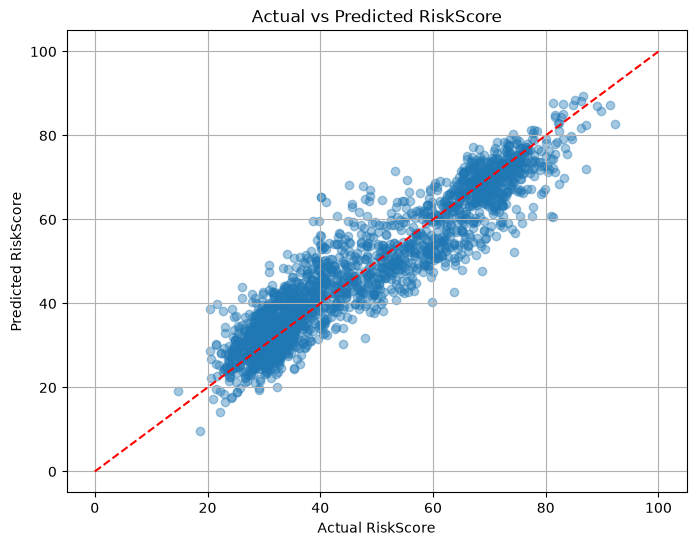

In [157]:
plt.figure(figsize=(8, 6))
plt.scatter(errors["Actual"], errors["Predicted"], alpha=0.4)
plt.plot([0, 100], [0, 100], "r--")
plt.xlabel("Actual RiskScore")
plt.ylabel("Predicted RiskScore")
plt.title("Actual vs Predicted RiskScore")
plt.grid()
plt.show()

График остатков

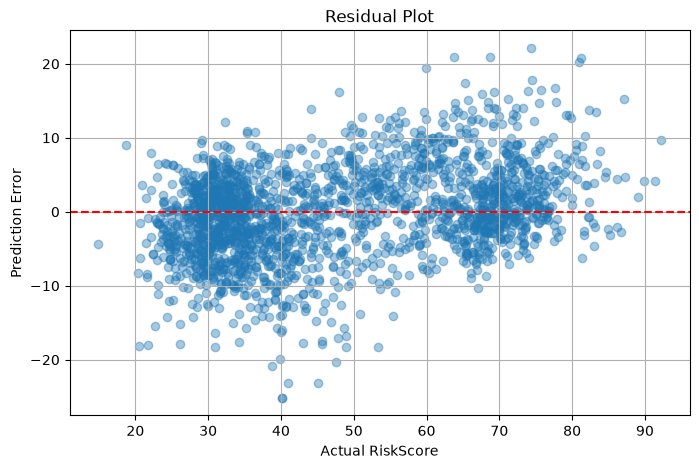

In [158]:
plt.figure(figsize=(8, 5))
plt.scatter(errors["Actual"], errors["Error"], alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Actual RiskScore")
plt.ylabel("Prediction Error")
plt.title("Residual Plot")
plt.grid()
plt.show()

MSE по диапазонам фактического RiskScore

In [127]:
errors["ScoreGroup"] = pd.cut(
    errors["Actual"],
    bins=[0, 35, 65, 100],
    labels=["Низкий (0–35)", "Средний (35–65)", "Высокий (65–100)"],
    include_lowest=True
)

group_errors = errors.groupby("ScoreGroup", observed=False).agg(
    Count=("SquaredError", "count"),
    MSE=("SquaredError", "mean"),
    MeanActual=("Actual", "mean"),
    MeanPredicted=("Predicted", "mean")
)

display(group_errors)

,Count,MSE,MeanActual,MeanPredicted
ScoreGroup,,,,
Низкий (0–35),711,52.068240,30.008214,32.687375
Средний (35–65),829,53.595731,48.349628,48.862010
Высокий (65–100),515,56.731640,71.856773,68.061763


Анализ ошибок по группам целевой переменной показал, что модель имеет тенденцию завышать низкие значения RiskScore и занижать высокие. Наиболее высокая ошибка наблюдается в группе высоких значений (MSE = 56.73), а наименьшая — в группе низких значений (MSE = 52.07). Это может свидетельствовать о недостаточной способности линейной модели описывать зависимости на краях диапазона целевой переменной.

### 7. Выводы и дальнейшие эксперименты

ПРоверим взаимодействие

In [196]:
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# Четыре основных признака
features_to_interact = [
    "CreditScore",
    "MonthlyIncome",
    "BaseInterestRate",
    "TotalDebtToIncomeRatio"
]

# Все возможные пары
interactions = [
    ("CreditScore", "MonthlyIncome"),
    ("CreditScore", "BaseInterestRate"),
    ("CreditScore", "TotalDebtToIncomeRatio"),
    ("MonthlyIncome", "BaseInterestRate"),
    ("MonthlyIncome", "TotalDebtToIncomeRatio"),
    ("BaseInterestRate", "TotalDebtToIncomeRatio"),
    ("MonthlyIncome", "BaseInterestRate"),
    ("CreditScore", "MonthlyIncome"),
    ("CreditScore", "BaseInterestRate"),
    ("CreditScore", "TotalDebtToIncomeRatio")
]

results = []

for feature_1, feature_2 in interactions:

    X_tr = X_train_z.copy()
    X_vl = X_val_z.copy()

    # Создаем взаимодействие на стандартизированных признаках
    interaction_name = f"{feature_1}_x_{feature_2}"

    X_tr[interaction_name] = (
        X_tr[feature_1] * X_tr[feature_2]
    )

    X_vl[interaction_name] = (
        X_vl[feature_1] * X_vl[feature_2]
    )

    # Стандартизируем новый признак по обучающей выборке
    interaction_mean = X_tr[interaction_name].mean()
    interaction_std = X_tr[interaction_name].std(ddof=0)

    if interaction_std == 0:
        interaction_std = 1

    X_tr[interaction_name] = (
        X_tr[interaction_name] - interaction_mean
    ) / interaction_std

    X_vl[interaction_name] = (
        X_vl[interaction_name] - interaction_mean
    ) / interaction_std

    # Обучаем модель
    model = MyLinearRegression()
    model.fit(X_tr, y_train)

    predictions = model.predict(X_vl)

    mse = mean_squared_error(y_val, predictions)

    results.append({
        "Interaction": interaction_name,
        "MSE": mse,
        "Improvement": 37.7688 - mse
    })

interaction_results = pd.DataFrame(results)
interaction_results = interaction_results.sort_values("MSE")

display(interaction_results)


,Interaction,MSE,Improvement
3,MonthlyIncome_x_BaseInterestRate,36.575999,1.192801
6,MonthlyIncome_x_BaseInterestRate,36.575999,1.192801
7,CreditScore_x_MonthlyIncome,36.627567,1.141233
0,CreditScore_x_MonthlyIncome,36.627567,1.141233
5,BaseInterestRate_x_TotalDebtToIncomeRatio,36.949090,0.819710
1,CreditScore_x_BaseInterestRate,37.033333,0.735467
8,CreditScore_x_BaseInterestRate,37.033333,0.735467
2,CreditScore_x_TotalDebtToIncomeRatio,37.154118,0.614682
9,CreditScore_x_TotalDebtToIncomeRatio,37.154118,0.614682
4,MonthlyIncome_x_TotalDebtToIncomeRatio,37.328423,0.440377


In [186]:
X_train_inter = X_train_z.copy()
X_val_inter = X_val_z.copy()

# Добавляем два лучших взаимодействия
best_interactions = [
    ("MonthlyIncome", "BaseInterestRate"),
    ("CreditScore", "MonthlyIncome")
]

for feature_1, feature_2 in best_interactions:

    name = f"{feature_1}_x_{feature_2}"

    X_train_inter[name] = (
        X_train_inter[feature_1] * X_train_inter[feature_2]
    )

    X_val_inter[name] = (
        X_val_inter[feature_1] * X_val_inter[feature_2]
    )

    # Масштабируем новый признак по обучающей выборке
    mean = X_train_inter[name].mean()
    std = X_train_inter[name].std(ddof=0)

    if std == 0:
        std = 1

    X_train_inter[name] = (
        X_train_inter[name] - mean
    ) / std

    X_val_inter[name] = (
        X_val_inter[name] - mean
    ) / std

# Обучаем модель
interaction_model = MyLinearRegression()
interaction_model.fit(X_train_inter, y_train)

# Оцениваем качество
y_pred_inter = interaction_model.predict(X_val_inter)

mse_inter = mean_squared_error(y_val, y_pred_inter)

print("MSE с двумя взаимодействиями:", mse_inter)


MSE с двумя взаимодействиями: 36.51038602169383


In [187]:
triple_interactions = [
    (
        "CreditScore",
        "MonthlyIncome",
        "BaseInterestRate"
    ),
    (
        "CreditScore",
        "MonthlyIncome",
        "TotalDebtToIncomeRatio"
    ),
    (
        "MonthlyIncome",
        "BaseInterestRate",
        "TotalDebtToIncomeRatio"
    )
]

triple_results = []

for features in triple_interactions:

    X_tr = X_train_inter.copy()
    X_vl = X_val_inter.copy()

    name = "_x_".join(features)

    X_tr[name] = (
        X_tr[features[0]]
        * X_tr[features[1]]
        * X_tr[features[2]]
    )

    X_vl[name] = (
        X_vl[features[0]]
        * X_vl[features[1]]
        * X_vl[features[2]]
    )

    mean = X_tr[name].mean()
    std = X_tr[name].std(ddof=0)

    if std == 0:
        std = 1

    X_tr[name] = (X_tr[name] - mean) / std
    X_vl[name] = (X_vl[name] - mean) / std

    model = MyLinearRegression()
    model.fit(X_tr, y_train)

    predictions = model.predict(X_vl)

    mse = mean_squared_error(y_val, predictions)

    triple_results.append({
        "Interaction": name,
        "MSE": mse,
        "Improvement": 37.180252836879546 - mse
    })

triple_results = pd.DataFrame(triple_results)
display(triple_results.sort_values("MSE"))


,Interaction,MSE,Improvement
0,CreditScore_x_MonthlyIncome_x_BaseInterestRate,35.067336,2.112917
2,MonthlyIncome_x_BaseInterestRate_x_TotalDebtTo...,36.295163,0.885090
1,CreditScore_x_MonthlyIncome_x_TotalDebtToIncom...,36.396469,0.783784


In [188]:
# Формируем нашу лучшую модель:
# исходные признаки + два лучших парных взаимодействия
X_train_best = X_train_inter.copy()
X_val_best = X_val_inter.copy()

# Добавляем лучшее тройное взаимодействие
triple_name = (
    "CreditScore_x_MonthlyIncome_x_BaseInterestRate"
)

X_train_best[triple_name] = (
    X_train_best["CreditScore"]
    * X_train_best["MonthlyIncome"]
    * X_train_best["BaseInterestRate"]
)

X_val_best[triple_name] = (
    X_val_best["CreditScore"]
    * X_val_best["MonthlyIncome"]
    * X_val_best["BaseInterestRate"]
)

# Масштабируем тройное взаимодействие
mean = X_train_best[triple_name].mean()
std = X_train_best[triple_name].std(ddof=0)

if std == 0:
    std = 1

X_train_best[triple_name] = (
    X_train_best[triple_name] - mean
) / std

X_val_best[triple_name] = (
    X_val_best[triple_name] - mean
) / std


# Проверяем оставшиеся парные взаимодействия
remaining_pairs = [
    ("CreditScore", "BaseInterestRate"),
    ("CreditScore", "TotalDebtToIncomeRatio"),
    ("MonthlyIncome", "TotalDebtToIncomeRatio"),
    ("BaseInterestRate", "TotalDebtToIncomeRatio")
]

additional_results = []

for feature_1, feature_2 in remaining_pairs:

    X_tr = X_train_best.copy()
    X_vl = X_val_best.copy()

    name = f"{feature_1}_x_{feature_2}"

    X_tr[name] = X_tr[feature_1] * X_tr[feature_2]
    X_vl[name] = X_vl[feature_1] * X_vl[feature_2]

    mean = X_tr[name].mean()
    std = X_tr[name].std(ddof=0)

    if std == 0:
        std = 1

    X_tr[name] = (X_tr[name] - mean) / std
    X_vl[name] = (X_vl[name] - mean) / std

    model = MyLinearRegression()
    model.fit(X_tr, y_train)

    predictions = model.predict(X_vl)
    mse = mean_squared_error(y_val, predictions)

    additional_results.append({
        "Interaction": name,
        "MSE": mse,
        "Improvement": 35.694408 - mse
    })

additional_results = pd.DataFrame(additional_results)
display(additional_results.sort_values("MSE"))


,Interaction,MSE,Improvement
0,CreditScore_x_BaseInterestRate,34.797131,0.897277
1,CreditScore_x_TotalDebtToIncomeRatio,34.994190,0.700218
3,BaseInterestRate_x_TotalDebtToIncomeRatio,35.060967,0.633441
2,MonthlyIncome_x_TotalDebtToIncomeRatio,35.124611,0.569797


### Проверим устойчивость выборки 35.4696

5 разделений

In [203]:
best_pairs = [
    ("MonthlyIncome", "BaseInterestRate"),
    ("CreditScore", "MonthlyIncome"),
    ("CreditScore", "BaseInterestRate")
]

best_triple = (
    "CreditScore",
    "MonthlyIncome",
    "BaseInterestRate"
)

In [204]:
def my_kfold(n_samples, n_splits=5, shuffle=True, random_state=42):
    indices = np.arange(n_samples)

    if shuffle:
        rng = np.random.default_rng(random_state)
        rng.shuffle(indices)

    folds = np.array_split(indices, n_splits)

    for i in range(n_splits):
        val_indices = folds[i]
        train_indices = np.concatenate(
            [folds[j] for j in range(n_splits) if j != i]
        )

        yield train_indices, val_indices


def my_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


In [205]:

fold_mse_scores = []

for fold_number, (train_idx, val_idx) in enumerate(
    my_kfold(len(X_train), n_splits=5),
    start=1
):
    # Разделяем данные на обучающую и проверочную части
    X_fold_train = X_train.iloc[train_idx].copy()
    X_fold_val = X_train.iloc[val_idx].copy()

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Стандартизация только по обучающей части фолда
    fold_mean = X_fold_train.mean()
    fold_std = X_fold_train.std(ddof=0).replace(0, 1)

    X_fold_train = (X_fold_train - fold_mean) / fold_std
    X_fold_val = (X_fold_val - fold_mean) / fold_std

    # Добавляем лучшие парные взаимодействия
    for feature_1, feature_2 in best_pairs:

        name = f"{feature_1}_x_{feature_2}"

        X_fold_train[name] = (
            X_fold_train[feature_1] *
            X_fold_train[feature_2]
        )

        X_fold_val[name] = (
            X_fold_val[feature_1] *
            X_fold_val[feature_2]
        )

        # Масштабируем взаимодействие по train-фолду
        mean = X_fold_train[name].mean()
        std = X_fold_train[name].std(ddof=0)

        if std == 0:
            std = 1

        X_fold_train[name] = (
            X_fold_train[name] - mean
        ) / std

        X_fold_val[name] = (
            X_fold_val[name] - mean
        ) / std

    # Добавляем лучшее тройное взаимодействие
    name = "_x_".join(best_triple)

    X_fold_train[name] = (
        X_fold_train[best_triple[0]] *
        X_fold_train[best_triple[1]] *
        X_fold_train[best_triple[2]]
    )

    X_fold_val[name] = (
        X_fold_val[best_triple[0]] *
        X_fold_val[best_triple[1]] *
        X_fold_val[best_triple[2]]
    )

    mean = X_fold_train[name].mean()
    std = X_fold_train[name].std(ddof=0)

    if std == 0:
        std = 1

    X_fold_train[name] = (
        X_fold_train[name] - mean
    ) / std

    X_fold_val[name] = (
        X_fold_val[name] - mean
    ) / std

    # Обучаем модель
    model = MyLinearRegression()
    model.fit(
        X_fold_train.to_numpy(dtype=float),
        y_fold_train.to_numpy(dtype=float)
    )

    predictions = model.predict(
        X_fold_val.to_numpy(dtype=float)
    )

    fold_mse = my_mse(
        y_fold_val.to_numpy(dtype=float),
        predictions
    )

    fold_mse_scores.append(fold_mse)

    print(f"Fold {fold_number} MSE: {fold_mse:.4f}")

print("\nСредний MSE:", np.mean(fold_mse_scores))
print("Стандартное отклонение MSE:", np.std(fold_mse_scores))


Fold 1 MSE: 34.7223
Fold 2 MSE: 31.5142
Fold 3 MSE: 34.0916
Fold 4 MSE: 34.9853
Fold 5 MSE: 33.9234

Средний MSE: 33.84737602009601
Стандартное отклонение MSE: 1.2304115969340743


In [206]:
class MyRidgeRegression:
    def __init__(self, alpha=1.0):
        self.alpha = alpha
        self.weights = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        # Добавляем столбец единиц для свободного коэффициента
        X_bias = np.c_[np.ones(X.shape[0]), X]

        # Матрица регуляризации
        penalty = np.eye(X_bias.shape[1])

        # Не штрафуем свободный коэффициент (intercept)
        penalty[0, 0] = 0

        # Аналитическое решение Ridge-регрессии
        self.weights = np.linalg.pinv(
            X_bias.T @ X_bias + self.alpha * penalty
        ) @ X_bias.T @ y

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        X_bias = np.c_[np.ones(X.shape[0]), X]

        return X_bias @ self.weights


Значения в норме,значит такое изменение выборки дало хороший результат

In [212]:
alphas = [0.00001, 0.0001, 0.001, 0.005, 0.01, 0.02, 0.05]
ridge_results = []

for alpha in alphas:

    fold_scores = []

    for train_idx, val_idx in my_kfold(
        len(X_train), n_splits=5
    ):
        X_fold_train = X_train.iloc[train_idx].copy()
        X_fold_val = X_train.iloc[val_idx].copy()

        y_fold_train = y_train.iloc[train_idx].to_numpy(dtype=float)
        y_fold_val = y_train.iloc[val_idx].to_numpy(dtype=float)

        # Масштабируем исходные признаки
        mean = X_fold_train.mean()
        std = X_fold_train.std(ddof=0).replace(0, 1)

        X_fold_train = (X_fold_train - mean) / std
        X_fold_val = (X_fold_val - mean) / std

        # Добавляем три парных взаимодействия
        for f1, f2 in best_pairs:
            name = f"{f1}_x_{f2}"

            X_fold_train[name] = X_fold_train[f1] * X_fold_train[f2]
            X_fold_val[name] = X_fold_val[f1] * X_fold_val[f2]

            m = X_fold_train[name].mean()
            s = X_fold_train[name].std(ddof=0)

            if s == 0:
                s = 1

            X_fold_train[name] = (X_fold_train[name] - m) / s
            X_fold_val[name] = (X_fold_val[name] - m) / s

        # Добавляем тройное взаимодействие
        name = "_x_".join(best_triple)

        X_fold_train[name] = (
            X_fold_train[best_triple[0]]
            * X_fold_train[best_triple[1]]
            * X_fold_train[best_triple[2]]
        )

        X_fold_val[name] = (
            X_fold_val[best_triple[0]]
            * X_fold_val[best_triple[1]]
            * X_fold_val[best_triple[2]]
        )

        m = X_fold_train[name].mean()
        s = X_fold_train[name].std(ddof=0)

        if s == 0:
            s = 1

        X_fold_train[name] = (X_fold_train[name] - m) / s
        X_fold_val[name] = (X_fold_val[name] - m) / s

        # Обучаем Ridge
        model = MyRidgeRegression(alpha=alpha)

        model.fit(
            X_fold_train.to_numpy(dtype=float),
            y_fold_train
        )

        predictions = model.predict(
            X_fold_val.to_numpy(dtype=float)
        )

        fold_scores.append(my_mse(y_fold_val, predictions))

    ridge_results.append({
        "Alpha": alpha,
        "Mean MSE": np.mean(fold_scores),
        "Std MSE": np.std(fold_scores)
    })

display(pd.DataFrame(ridge_results))


,Alpha,Mean MSE,Std MSE
0,0.00001,33.813688,1.263539
1,0.00010,33.813687,1.263539
2,0.00100,33.813682,1.263544
3,0.00500,33.813662,1.263562
4,0.01000,33.813638,1.263584
5,0.02000,33.813596,1.263627
6,0.05000,33.813515,1.263746


Вывод, фиксируем альфа 0.005

Попробуем новые преобразования признаков

In [215]:
alpha = 0.005
fold_scores = []

for train_idx, val_idx in my_kfold(len(X_train), n_splits=5):

    X_fold_train = X_train.iloc[train_idx].copy()
    X_fold_val = X_train.iloc[val_idx].copy()

    y_fold_train = y_train.iloc[train_idx].to_numpy(dtype=float)
    y_fold_val = y_train.iloc[val_idx].to_numpy(dtype=float)

    # Масштабируем исходные признаки
    mean = X_fold_train.mean()
    std = X_fold_train.std(ddof=0).replace(0, 1)

    X_fold_train = (X_fold_train - mean) / std
    X_fold_val = (X_fold_val - mean) / std

    # Обучаем Ridge
    model = MyRidgeRegression(alpha=alpha)

    model.fit(
        X_fold_train.to_numpy(dtype=float),
        y_fold_train
    )

    predictions = model.predict(
        X_fold_val.to_numpy(dtype=float)
    )

    fold_scores.append(my_mse(y_fold_val, predictions))

print("MSE каждого фолда:", fold_scores)
print("Средний MSE:", np.mean(fold_scores))
print("Стандартное отклонение MSE:", np.std(fold_scores))

MSE каждого фолда: [np.float64(36.38295134594165), np.float64(33.49222094501337), np.float64(35.583378840734674), np.float64(37.45134141651573), np.float64(35.38776273998017)]
Средний MSE: 35.65953105763712
Стандартное отклонение MSE: 1.3046694277569102


In [218]:
# Обучаем модель на всей тренировочной выборке
model = MyRidgeRegression(alpha=0.005)

model.fit(
    X_train_z.to_numpy(dtype=float),
    y_train.to_numpy(dtype=float)
)

# Получаем предсказания для всей проверочной выборки
predictions = model.predict(
    X_val_z.to_numpy(dtype=float)
)

print("Размер y_val:", len(y_val))
print("Размер predictions:", len(predictions))

Размер y_val: 2055
Размер predictions: 2055


In [219]:
errors = y_val.values - predictions

error_analysis = pd.DataFrame({
    "Actual": y_val.values,
    "Predicted": predictions,
    "Error": errors,
    "AbsError": np.abs(errors)
})

error_analysis["RiskGroup"] = pd.cut(
    error_analysis["Actual"],
    bins=[0, 30, 50, 70, 100],
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

print(
    error_analysis.groupby("RiskGroup", observed=True)
    [["Actual", "Predicted", "Error", "AbsError"]]
    .mean()
)

                Actual  Predicted     Error  AbsError
RiskGroup                                            
Low          27.023921  29.302519 -2.278598  4.299267
Medium-Low   37.270601  39.104832 -1.834230  4.913706
Medium-High  61.497565  59.532693  1.964872  4.768246
High         75.034264  71.858237  3.176028  4.447730


In [220]:
print("Корреляция Actual и Predicted:",
      np.corrcoef(y_val, predictions)[0, 1])

print("Средний Actual:", np.mean(y_val))
print("Средний Predicted:", np.mean(predictions))

print("Минимальный Actual:", np.min(y_val))
print("Максимальный Actual:", np.max(y_val))

print("Минимальный Predicted:", np.min(predictions))
print("Максимальный Predicted:", np.max(predictions))

Корреляция Actual и Predicted: 0.9359646832368993
Средний Actual: 47.89485142599055
Средний Predicted: 48.0151693851347
Минимальный Actual: 14.841417296887238
Максимальный Actual: 92.26544192066936
Минимальный Predicted: 9.12211158404314
Максимальный Predicted: 89.24769121949078
